# Getting Started 

### <i> Roadscanners Frostbumps Data Cleaning

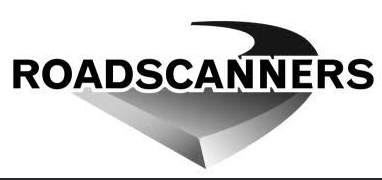

 ###  <i> Summary

This is a notebook to help you get started with the RoadScanners Frostbumps dataset. This notebook goes only over cleaning and some basic optimization, the rest I leave up to your team!


---

### <i> Loading the dataset

|Step|Decription|
|---|---|
|<strong style='color:Yellow'>1 </strong>| <strong style='color:Yellow'>Loading the dataset </strong> |
|2| Fixing datatypes|
|3| Fixing timeseries continuity|
|4| Fixing missing values|
|5| Fixing annotation bug|
|6| Isolating Frostbump annotations|

<br>

It's pretty simple, use a space delimiter from the `pd.read_csv()` method or use the `pd.read_txt()` method. Either works. 

Load the data locally to prevent dataleaks.

In [61]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

# Loading dataset (NOT in the Git repo). Set the separator as white spaces
df = pd.read_csv(
    r"C:\frostbumps2026\Iisingintie_Acc1_m800_RDMC_2026-05-06_123750.txt",
    sep="\t",
)

df

C:\Users\tuomas.valtanen\AppData\Local\Temp\ipykernel_2532\567953104.py:9: DtypeWarning: Columns (18: posneg, 19: vaikeus, 20: muu) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(


,Num,Timer(ms),Loc(m),Speed (m/s),East(m),North(m),CElev(m),Roll(deg),Pitch(deg),Yaw(deg),...,AccY,AccZ,GyrX,GyrY,GyrZ,RBCSV_80(cf),RBCSV_60(cf),posneg,vaikeus,muu
0,1,45476731,"3767,52","0,035","426290,475","7414101,054","107,049","1,6195","-1,7959","13,5969",...,"0,2478","9,84059","-0,00239","0,00271","-0,00435","0,87092","0,85334",0,0,0
1,2,"45476733,5","3767,52","0,035","426290,475","7414101,054","107,049","1,6197","-1,7954","13,5971",...,"0,22563","9,83939","-0,00394","0,00529","-0,00295","0,87092","0,85334",0,0,0
2,3,"45476728,5","3767,52","0,035","426290,475","7414101,054","107,048","1,6192","-1,7961","13,5968",...,"0,25581","9,83537","-0,00354","0,00251","-0,00404","0,87092","0,85334",0,0,0
3,4,45476736,"3767,52","0,035","426290,475","7414101,054","107,049","1,6196","-1,7955","13,5979",...,"0,22451","9,83531","-0,0054","0,00077","0,00153","0,87092","0,85334",0,0,0
4,5,45476726,"3767,52","0,035","426290,475","7414101,054","107,048","1,619","-1,7962","13,5968",...,"0,27895","9,82614","-0,00743","-0,0013","-0,00236","0,87092","0,85334",0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
69120,69121,"45645353,5","6937,281","0,34","423656,379","7415796,484","119,998","-2,7993","-1,5079","174,9501",...,"-0,42211","10,04348","0,00553","-0,01712","-0,01099","2,64943","2,24766",0,0,0
69121,69122,45645356,"6937,282","0,34","423656,378","7415796,485","119,999","-2,7977","-1,51","174,9488",...,"-0,46829","10,08303","0,00599","-0,01322","-0,01395","2,64943","2,24739",0,0,0
69122,69123,"45645358,5","6937,282","0,34","423656,377","7415796,485","119,999","-2,7962","-1,5123","174,9476",...,"-0,46265","10,0552","0,00566","-0,01423","-0,01327","2,64943","2,24739",0,0,0
69123,69124,45645361,"6937,283","0,34","423656,377","7415796,486","119,999","-2,7942","-1,5148","174,9462",...,"-0,43237","10,07363","0,00843","-0,01578","-0,01478","2,64943","2,24739",0,0,0


---

### <i> Fixing datatypes

|Step|Decription|
|---|---|
|1|  Loading the dataset|
|<strong style='color:Yellow'>2|<strong style='color:Yellow'> Fixing datatypes|
|3| Fixing timeseries continuity|
|4| Fixing missing values|
|5| Fixing annotation bug|
|6| Isolating Frostbump annotations|

<br>
<br>

The first step is to fix the commas. 

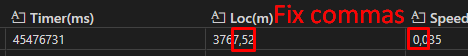


In [62]:
# Let's use a loop method.

# List ALL the columns in a variable
columns = df.columns

# For each column...
for column in columns:
    # If the column dtype is already numeric... SKIP
    if pd.api.types.is_numeric_dtype(df[column]):
        continue
    
    # Otherwise, replace ANY commas with periods.
    df[column] = df[column].str.replace(",",".")

    # And replace it to a float value. 
    df[column] = df[column].astype(float)

# This should cover each edge-case, since there are no string-type 
# intended columns for this dataset.
df.head(3)

,Num,Timer(ms),Loc(m),Speed (m/s),East(m),North(m),CElev(m),Roll(deg),Pitch(deg),Yaw(deg),...,AccY,AccZ,GyrX,GyrY,GyrZ,RBCSV_80(cf),RBCSV_60(cf),posneg,vaikeus,muu
0,1,45476731.0,3767.52,0.035,426290.475,7414101.054,107.049,1.6195,-1.7959,13.5969,...,0.24780,9.84059,-0.00239,0.00271,-0.00435,0.87092,0.85334,0.0,0.0,0.0
1,2,45476733.5,3767.52,0.035,426290.475,7414101.054,107.049,1.6197,-1.7954,13.5971,...,0.22563,9.83939,-0.00394,0.00529,-0.00295,0.87092,0.85334,0.0,0.0,0.0
2,3,45476728.5,3767.52,0.035,426290.475,7414101.054,107.048,1.6192,-1.7961,13.5968,...,0.25581,9.83537,-0.00354,0.00251,-0.00404,0.87092,0.85334,0.0,0.0,0.0


---


### <i> Fixing timeseries continuity

|Step|Decription|
|---|---|
|1|  Loading the dataset|
|2| Fixing datatypes|
|<strong style='color:Yellow'>3|<strong style='color:Yellow'> Fixing timeseries continuity|
|4| Fixing missing values|
|5| Fixing annotation bug|
|6| Isolating Frostbump annotations|

<br>
<br> 

<div style="border: 2px dashed white; padding: 10px; box-sizing: border-box;">


Timo mentioned when introducing the semester project that there were bugs/flaws with the instruments at the beginning of each road test and what I'm about to show you is likely what he was mentioning:

<br>
<br> 

<strong><u> The problem: </u></strong>

At the beginning of each dataset in the `Timer(ms)` column, the observation instruments have a strange lag.

<br>
<br>


If you recall time-series requirements from Tuomas' lectures earlier, <strong style='color:teal ;'>  timeseries datasets have a sequence column which MUST</strong>:

<br>

<div style="border: 1px solid white; padding: 10px; box-sizing: border-box;">


* <strong> Be equally spaced </strong>

* <strong> Have no breaks in the sequence  </strong>

</div>

<br>


<strong style='color:green ; background-color:black;'>If any of these two requirements fail, they must be fixed to re-obtain the continuity from that dataset. </strong>

<br>
<br>

Now take a look at the following below:

<br>
<br>

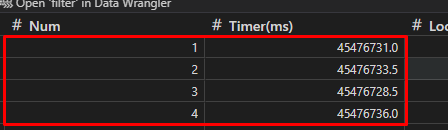


<br>
<br>

<strong style='color:teal ;'> We observe that the `Timer(ms)` values are not equally spaced. This breaks the dataset's time series sequentiality and must be fixed. </strong>

<br>




</div>



<Axes: xlabel='Num', ylabel='Timer(ms)'>

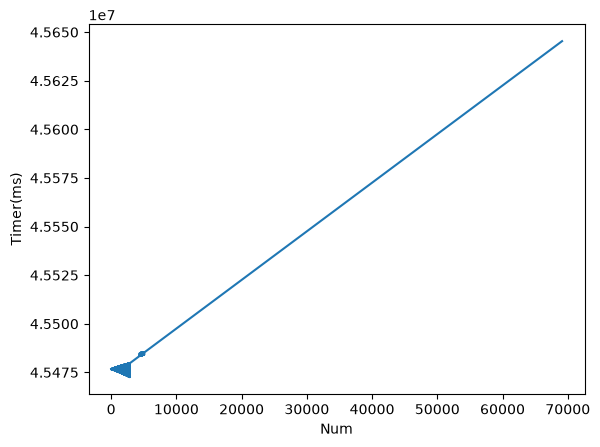

In [63]:
# Visual showing the sequential discontinuity.
sns.lineplot(df, x="Num", y="Timer(ms)")

<div style="border: 3px dashed white; padding: 10px; box-sizing: border-box;">

<i>

Notice above, that our <strong style='color:teal'><u> discontinuity exists AT THE START of the dataset. That is great news. </u></strong>

<br>
<br>


Now you might be asking: <strong style='color:yellow'>"So, what's so great about the time-sequence discontinuity being at the start of the dataset?" </strong>

<br>
<br>


Because normally, to fix this issue, one would have to employ more tedious approaches to fix it. 

<div style="border: 1px solid white; padding: 10px; box-sizing: border-box;">
To name a few:

<br>

* Interpolation / extrapolation

* Imputation 

* Resampling

* Splitting into different segments

</div>

<br>
<br>

But since the issue is at the beginning of the dataset:

<br>
<br>


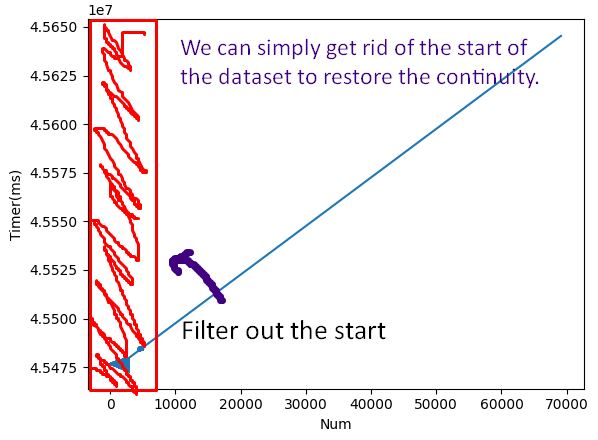

<br>
<br>

And that is a perfectly valid solution, because:

</i>

|Reason|Justification|
|---|---|
|<strong style='color:Teal'>Reason 1</strong>|Simplicity. It's a intuitive fix. |
|<strong style='color:Purple'>Reason 2</strong>| Any probabilistic/imputation methods to fix continuity will make any model more inaccurate. In this case, we're not hurting our model scores by 'guessing'/imputing anything. |
|<strong style='color:Green'>Reason 3</strong>| <strong>We cannot trust that the instruments used are accurate while this bug is occurring (HUGE reason).</strong>|

<br>
<br>

<i>




In [64]:
# Fixing it is simple, cut off the starting portions of that dataset until
# no more problems exist. 
df = df[df["Num"] > 6000]

<Axes: xlabel='Num', ylabel='Timer(ms)'>

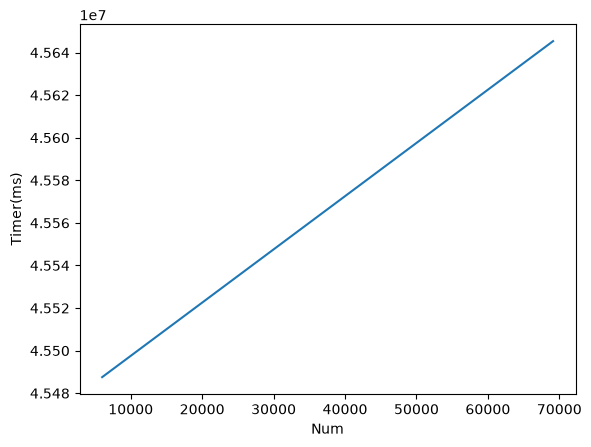

In [65]:
# Fixed the sequency break. 
sns.lineplot(df, x="Num", y="Timer(ms)")

---

### <i> Fixing Missing Values

|Step|Decription|
|---|---|
|1|  Loading the dataset|
|2| Fixing datatypes|
|3| Fixing timeseries continuity|
|<strong style='color:Yellow'>4|<strong style='color:Yellow'> Fixing missing values|
|5| Fixing annotation bug|
|6| Isolating Frostbump annotations|


<br>
<br>

<div style="border: 3px dashed white; padding: 10px; box-sizing: border-box;">

<br>
<br>


<u> <strong> The problem: </strong></u>

When inspecting for missing values within the dataset, we see the following:

<br>
<br> 

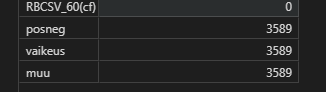

<br>
<br> 

<strong style='color:orange'>Missing values are serious trouble for datasets because <u> you cannot drop them under normal circumstances. See below for why:</u> </strong>

<br>
<br> 

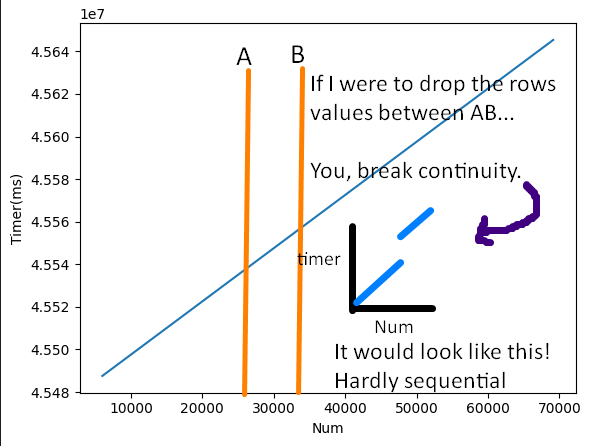

<br>
<br> 

Typically you would impute these values instead if that were the case. But as you'll see below, we get quite lucky...

</div>



In [66]:
# Check all the way at the bottom of the output.
# We're missing values.
df.isna().sum()

Num                0
Timer(ms)          0
Loc(m)             0
Speed (m/s)        0
East(m)            0
North(m)           0
CElev(m)           0
Roll(deg)          0
Pitch(deg)         0
Yaw(deg)           0
AccX               0
AccY               0
AccZ               0
GyrX               0
GyrY               0
GyrZ               0
RBCSV_80(cf)       0
RBCSV_60(cf)       0
posneg          3589
vaikeus         3589
muu             3589
dtype: int64

<div style="border: 3px dashed white; padding: 10px; box-sizing: border-box;">

<i> Notice above that the <strong style='color:green'><u> number of missing annotations from Roadscanners is the same for all three columns: </u></strong>

<br>
<br>

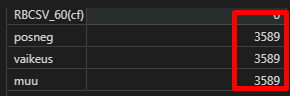

<br>
<br>

<h5> <strong style='color:teal'>

 This hints to us that  <u>the indices where these `NaN` values exist could be the same for all three columns. </u>


</strong> </h5>

<br>

Let's make a test which confirms that the `NaN`s are all in the same location for each column.

</div>



In [67]:
# List of column names
columns = ["posneg", "vaikeus", "muu"]

# This creates a pandas series that gives True or False
# If the value is `Nan` then True. (Boolean mask)
reference = df[columns[0]].isna()

# For each column, cross reference the other columns whether
# each row has missing values in those exact rows.
for col in columns[1:]:
    if not reference.equals(df[col].isna()):
        print(f"{col} has NaNs in different locations")
    else:
        print("NaNs fall in the same locations")

# We confirmed that all these `NaN` values are in the same location.

NaNs fall in the same locations
NaNs fall in the same locations


<i>

<div style="border: 3px dashed white; padding: 10px; box-sizing: border-box;">

<h5><strong style='color:green'>

We confirmed that all the `NaN`s are in the same location

</strong></h5>

<br>
<br>

Now, the question is: 

<strong><u>Where are the `NaN` values located? </strong></u>

<br>
<br>

For that, we'll use a simple `.fillna()` method trick:

<br>
<br>

We fill the `posneg` column values with a number that is impossible to achieve normally.

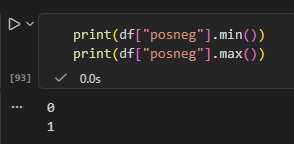


<br>
<br>

<h5><strong style='color: teal'>

In this case, `posneg` is intended to be a boolean `dtype` (zero or one), so  we `fillna()` the `posneg` column to the value `8` so we can visualize the locations with a `.lineplot`. 

</strong></h5>

</div>

<i>



<Axes: xlabel='Num', ylabel='posneg'>

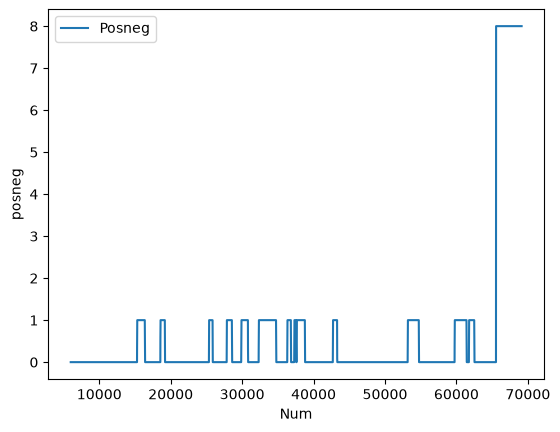

In [68]:
# I will now show the location of all these missing values.
test_df = df.copy()

# We are going to fill all our missing values in the `posneg` column with the number 8 instead.
# That way we CLEARLY see if it used to be a NaN value.
test_df["posneg"] = test_df["posneg"].fillna(8)

# Graphing.
sns.lineplot(test_df, x="Num", y="posneg", label="Posneg")



<i> 


<div style="border: 3px dashed white; padding: 10px; box-sizing: border-box;">

<u><strong style='color:Teal'>
All of the `Nan` values exist at the tail of the dataset!
</strong></u>

<br>
<br>


This means that the logical solution is to <strong style='color:Teal'>drop all of the `NaN` rows </strong> for the reasons below:
<div style="border: 1px solid white; padding: 10px; box-sizing: border-box;">

<strong>

* Dropping them doesn't break the sequential continuity.

* We REALLY want to avoid imputing/guessing our `target`. 

* `Speed(ms)` and other features also have erratic behavior at the end of the dataset. It's not reliable.

</strong>

</div>

<br>
<br>

As for why this bug occurred, I suspect this occured when placing/importing the data into the RoadScanners annotation/data observation software.



In [69]:
# The fix:
# Drop all the NaN values in the dataset.
df = df.dropna()

df.isna().sum()

# We can get away with this because these are the only rows left to drop.

Num             0
Timer(ms)       0
Loc(m)          0
Speed (m/s)     0
East(m)         0
North(m)        0
CElev(m)        0
Roll(deg)       0
Pitch(deg)      0
Yaw(deg)        0
AccX            0
AccY            0
AccZ            0
GyrX            0
GyrY            0
GyrZ            0
RBCSV_80(cf)    0
RBCSV_60(cf)    0
posneg          0
vaikeus         0
muu             0
dtype: int64

---

### <i> Annotation bug

|Step|Decription|
|---|---|
|1|  Loading the dataset|
|2| Fixing datatypes|
|3| Fixing timeseries continuity|
|4| Fixing missing values|
|<strong style='color:Yellow'>5|<strong style='color:Yellow'> Fixing annotation bug|
|6| Isolating Frostbump annotations|

<br>

`posneg` `muu` and `vaikeus` all have float values even though they are supposed to be integers.



In [70]:
# Here you can see these are not clearly all binary. This occurs
# for `vaikeus` and `muu` as well.
df["posneg"].value_counts()

posneg
0.000    46470
1.000    12562
0.517        4
0.971        4
0.164        4
         ...  
0.471        1
0.274        1
0.225        1
0.077        1
0.028        1
Name: count, Length: 385, dtype: int64

<i> 

Let me show you what the behavior of those decimal values look like:

<Axes: xlabel='Num', ylabel='posneg'>

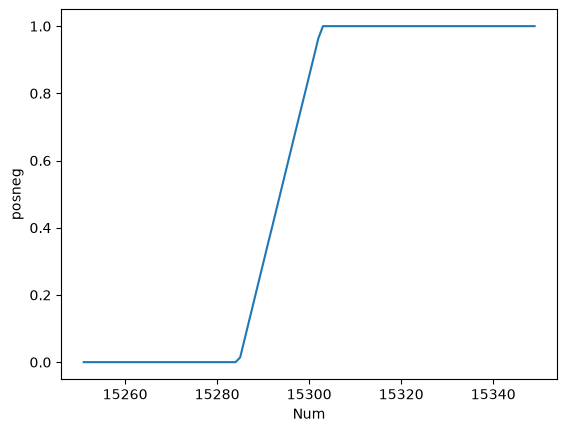

In [71]:
sns.lineplot(x="Num", y="posneg", data=df.query("Num > 15250 and Num < 15350"))

<Axes: xlabel='Num', ylabel='posneg'>

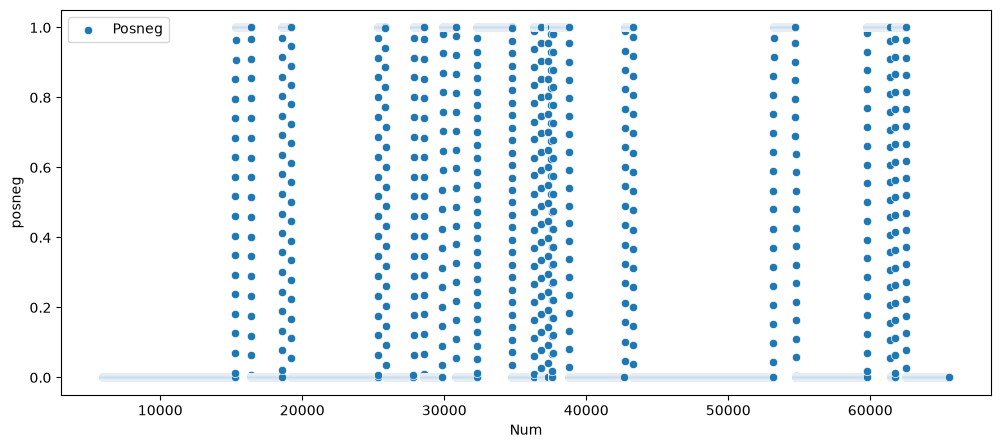

In [72]:
plt.figure(figsize=(12,5))

# Here you see the problem. 
sns.scatterplot(df, x="Num", y="posneg", label="Posneg")
# The values go up and down and know where they want to fall, but need time to get there. 
# Likely a sampling issue between the hardware & software.

<i>

We observe the following low-sampling behavior with the `posneg` `vaikeus` and `muu` variables.

* When values change from their stable position, they always end on an integer. 

* They also never reverse course. 


### <i> How to fix


<div style="border: 3px dashed white; padding: 10px; box-sizing: border-box;">

Fixing this problem is more difficult than it may seem. We cannot use `.round()`. The visual below explains that reasoning:

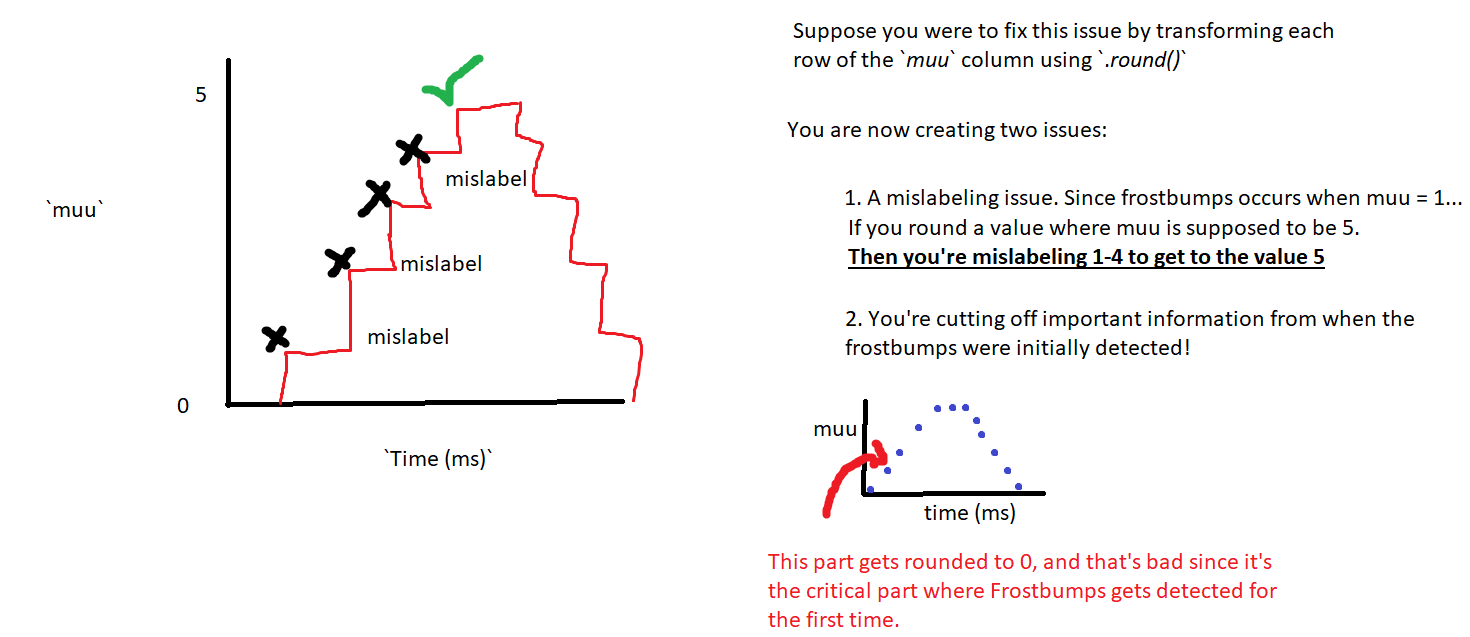

<br>
<br>

Therefore, instead, we'll be using a stable backfill approach. I'll explain the algorithm below:

</div>



### <i> Stable backfill  algorithm

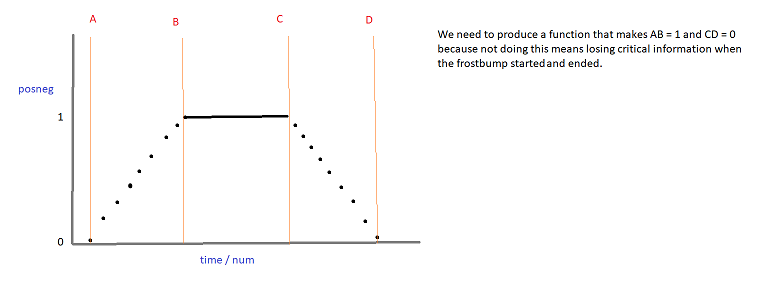

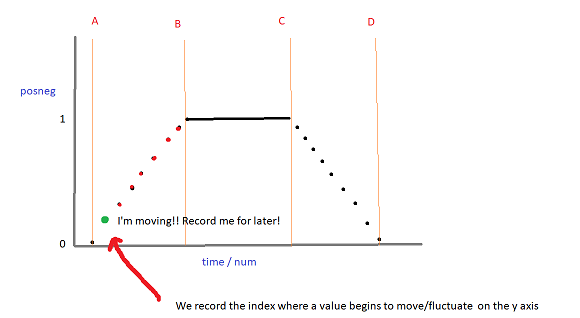

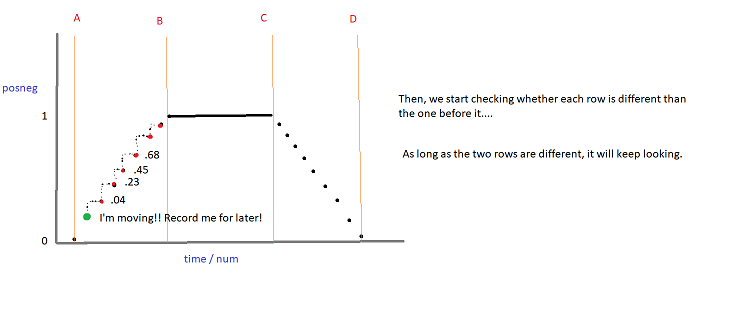

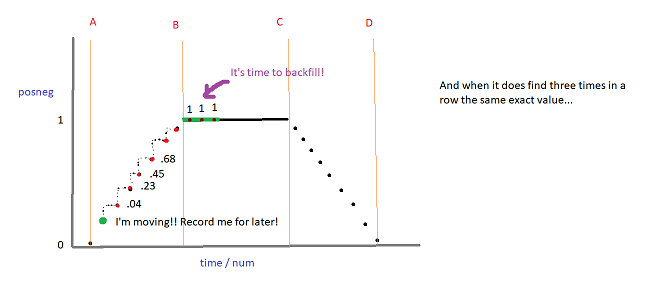

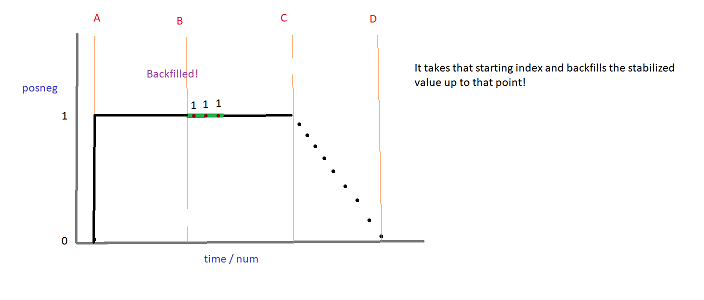

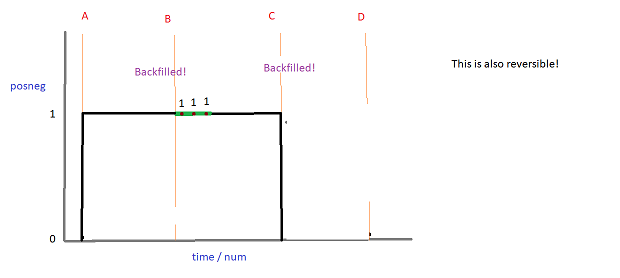

<i> This implementation does not work for one of the datasets given by Roadscanners. 

I will leave it to your team to find which dataset that is + how to adjust this function!

### <i> Function for the backfill

<br>


Here, I provide you with my solution for that annotation bug. 

This will not work on `Kaittiaisentie_Acc1_RDMC_2026-05-06_132147`

Find out why and make your own solution for that.

<br>
<br>

I trust you'll improve on my algorithm for that edge-case! (And please share, I'm curious!)

In [73]:
'''
This function fixes the majority of the Roadscanners annotation bugs for `muu` `vaikeus` and `posneg`

When a column moves more than the threshold, remember that a transition has started.
Once the column's rows has been stable for 3 rows, take the integer value it settled on and backfill 
that value all the way from the beginning of the transition.

df = pandas.dataframe() 
column = string of pandas column
threshold = int
'''

def backfiller(df, column, threshold):

    rows_required_before_backfill = 3

    # Did the value move far enough to start a transition?
    changed = df[column].diff().abs() > threshold

    # This creates a series
    # Where if it has NOT changed, True -- Otherwise we put it as False.
    stable = ~changed

    # This makes another series that checks stable. If stable is true
    # for 3 rows in a row, then output 1 (or True, whatever your preferred flavor is)
    settled = stable.rolling(rows_required_before_backfill).min() == 1 

    # We start by placing the normal values in the new column
    df[f"{column}"] = df[column]

    # empty variable where the start of the transition will go.
    transition_start = None

    # For loop... using index (not really optimized, sorry.)
    for i in df.index:

        # If a change has started and we don't have a starting
        # transition... mark the transition
        if changed.loc[i] and transition_start is None:
            transition_start = i

        # if the value has been settled...
        # AND the transition start isn't nothing(start).
        if settled.loc[i] and transition_start is not None:

            # The value at the settled point becomes the
            # value for the entire transition.
            settled_value = df.loc[i, column].round(0)

            df.loc[transition_start:i, f"{column}"] = settled_value

            # Transition is finished.
            transition_start = None

    return df

# Now we use this for all of the columns that have this problem.
backfiller(df,"posneg",.0001)
backfiller(df,"vaikeus",.0001)
backfiller(df,"muu",.0001)


,Num,Timer(ms),Loc(m),Speed (m/s),East(m),North(m),CElev(m),Roll(deg),Pitch(deg),Yaw(deg),...,AccY,AccZ,GyrX,GyrY,GyrZ,RBCSV_80(cf),RBCSV_60(cf),posneg,vaikeus,muu
6000,6001,45487553.5,3775.098,6.921,426284.838,7414106.228,107.406,0.7201,-5.2251,138.0078,...,0.03165,9.97104,-0.01721,0.01004,-0.00825,1.35772,1.12693,0.0,0.0,0.0
6001,6002,45487556.0,3775.116,6.930,426284.825,7414106.240,107.406,0.7187,-5.2252,138.0066,...,-0.11711,9.84203,-0.01653,0.00277,-0.01302,1.35825,1.12656,0.0,0.0,0.0
6002,6003,45487558.5,3775.133,6.938,426284.812,7414106.251,107.406,0.7180,-5.2231,138.0047,...,0.09574,9.81056,-0.01177,0.01816,-0.01785,1.35942,1.12427,0.0,0.0,0.0
6003,6004,45487561.0,3775.150,6.946,426284.799,7414106.262,107.406,0.7172,-5.2213,138.0025,...,0.13998,10.10058,-0.01271,0.01620,-0.02014,1.36059,1.12198,0.0,0.0,0.0
6004,6005,45487563.5,3775.168,6.954,426284.785,7414106.273,107.406,0.7164,-5.2204,138.0008,...,-0.01137,10.10700,-0.01250,0.01043,-0.01621,1.36176,1.11966,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
65531,65532,45636381.0,6884.251,15.433,423702.373,7415769.101,119.401,1.8303,-2.9219,157.7936,...,0.38593,9.65299,0.00830,0.01345,-0.01387,0.21638,0.14367,0.0,0.0,0.0
65532,65533,45636383.5,6884.289,15.428,423702.338,7415769.116,119.402,1.8322,-2.9223,157.7919,...,0.27497,9.38934,0.00779,-0.00259,-0.01639,0.21639,0.14366,0.0,0.0,0.0
65533,65534,45636386.0,6884.327,15.422,423702.303,7415769.132,119.402,1.8342,-2.9214,157.7904,...,0.11317,9.19849,0.00903,0.00738,-0.01457,0.21651,0.14374,0.0,0.0,0.0
65534,65535,45636388.5,6884.366,15.417,423702.268,7415769.148,119.402,1.8367,-2.9191,157.7891,...,0.13944,9.28944,0.01199,0.01692,-0.01406,0.21643,0.14369,0.0,0.0,0.0


<i> Now, we'll check to ensure it was fixed properly.

<Axes: xlabel='Num', ylabel='posneg'>

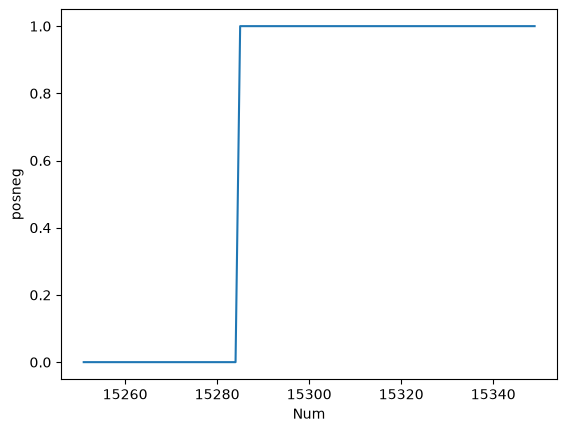

In [74]:
sns.lineplot(x="Num", y="posneg", data=df.query("Num > 15250 and Num < 15350"))

<Axes: xlabel='Num', ylabel='posneg'>

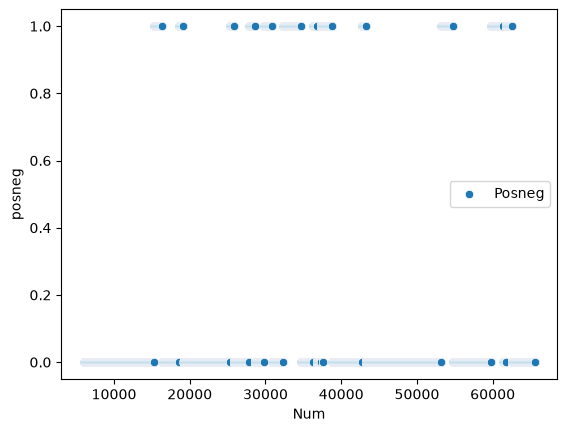

In [75]:
# Here is the result.
sns.scatterplot(df, x="Num", y="posneg", label="Posneg")

<i> We fixed it! 

Now, let's convert the `muu` `vaikeus` and `posneg` columns to their intended`int` dtype

In [76]:
# Now we can fix the datatypes for 
# `vaikeus` `muu` and `posneg`

columns = ["vaikeus", "muu", "posneg"]

for column in columns:
    df[column] = df[column].astype(int)

df.dtypes

Num               int64
Timer(ms)       float64
Loc(m)          float64
Speed (m/s)     float64
East(m)         float64
North(m)        float64
CElev(m)        float64
Roll(deg)       float64
Pitch(deg)      float64
Yaw(deg)        float64
AccX            float64
AccY            float64
AccZ            float64
GyrX            float64
GyrY            float64
GyrZ            float64
RBCSV_80(cf)    float64
RBCSV_60(cf)    float64
posneg            int64
vaikeus           int64
muu               int64
dtype: object

---

### <i> Isolating Frostbumps annotations.

|Step|Decription|
|---|---|
|1|  Loading the dataset|
|2| Fixing datatypes|
|3| Fixing timeseries continuity|
|4| Fixing missing values|
|5| Fixing annotation bug|
|<strong style='color:Yellow'>6|<strong style='color:Yellow'> Isolating Frostbump annotations|

<br>
<br>

<div style="border: 3px dashed white; padding: 10px; box-sizing: border-box;">

Next up, let's isolate the case where frostbumps exist (create the target column.)

<br>
<br>
 
Please look at the code snippet below: the Roadscanners `.docx` from the Teams environment :

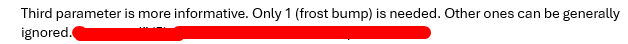

<br>
<br>

We can see that the document mentions directly when Frostbumps is occuring.

<br>

<h5><strong style='color:Teal'>If `muu = 1`, Frostbumps is occurring! </strong> </h5>

<br>
<br>

<div style="border: 1px solid white; padding: 10px; box-sizing: border-box;">

<u>Note: </u>

You can also use my approach: 

since `1` is frostbumps, and `2` is frostbumps during a turn (from translations). You can consider either and both of these values as Frostbumps being `True`

</div>

<br>
<br>

So, let's create a column that isolates those cases using a pandas multi-filter:

</div>



In [77]:
# Here we use an pandas boolean 'or' multi-filter. 
df["Frostbumps"] = (
    (df["muu"] == 1) |
    (df["muu"] == 2)
).astype(int)

In [78]:
# Viola, we now created a binary column that will serve as our target variable.
df["Frostbumps"]

6000     0
6001     0
6002     0
6003     0
6004     0
        ..
65531    0
65532    0
65533    0
65534    0
65535    0
Name: Frostbumps, Length: 59536, dtype: int64

---

### <i> Saving the cleaned dataset

In [79]:
df.to_csv(r"c:\frostbumps2026\05_cleaned_sinetänsalmentie_Acc1_m793_RDMC_2026-05-06_112757.csv")

<div style="border: 3px dashed white; padding: 10px; box-sizing: border-box;">
<i>

<h3>Mentions:</h3>

There is still quite a bit of work to do! I recommend performing these steps for each dataset and exploring the data yourself. 

I deliberately left out a ton of optimizations to let your team go at.

Here is a non-exhaustive list for you that might give you some ideas:

* I only cleaned 1 dataset.
* The backfill function I created does not work on one of the datasets! You'll need a special approach for that.
* I haven't done used interaction features, EDA, Feature engineering, and other ML optimization tools/techniques.
* Consider looking at the dataset from a noise perspective? Is it an issue or is it just fluctuations?
* How do we handle the speed column? 
* Which model might work best? Perhaps use t-SNE to check the complexity!
* Are the distributions going to be an issue? 

</div>